# 03 · Diagnostics and the long-run link (plan Steps 04–05)

This notebook covers unit roots, rolling stationarity, SARIMA against naive forecasts, Engle–Granger for Brent–WTI and HO−RB, and Johansen for the three-leg crack. It reads the outputs of `scripts/run_analysis.py`; run notebook 02 or the script first. All results are a **spot proxy**.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image
from oilrv.config import load_config, ROOT
T, F = ROOT / 'output/tables', ROOT / 'output/figures'
read = lambda n, **k: pd.read_csv(T / n, **k)

## Unit roots: legs and spreads (full sample)

In [2]:
read('03_unit_roots.csv', index_col=[0, 1])[['adf_stat', 'adf_p', 'kpss_p', 'adf_says', 'kpss_says']].round(4)

adf_stat   adf_p  kpss_p    adf_says       kpss_says
series    form                                                       
cl        level   -3.1156  0.0254  0.0100  stationary  not stationary
          diff   -11.3910  0.0000  0.1000  stationary      stationary
brent     level   -3.0692  0.0289  0.0100  stationary  not stationary
          diff   -11.3621  0.0000  0.1000  stationary      stationary
rb        level   -3.1310  0.0243  0.0138  stationary  not stationary
          diff   -12.7984  0.0000  0.1000  stationary      stationary
ho        level   -1.6828  0.4400  0.0100   unit root  not stationary
          diff   -13.4092  0.0000  0.1000  stationary      stationary
crack321  level   -4.0028  0.0014  0.0100  stationary  not stationary
          diff   -17.7559  0.0000  0.1000  stationary      stationary
brent_wti level   -3.8412  0.0025  0.0238  stationary  not stationary
          diff   -15.2778  0.0000  0.1000  stationary      stationary
ho_rb     level   -2.7423  0.0670  0.0100   unit root  not stationary
          diff   -13.0756  0.0000  0.1000  stationary      stationary

- **Price levels.** The tests disagree. ADF rejects a unit root at 5% for WTI, Brent and RBOB over 2007–26, because the sample swings between \$30 and \$140 several times. KPSS rejects stationarity for all four. ULSD keeps its unit root on ADF.
- **First differences** are clearly stationary.
- **Spreads.** ADF says the crack (p = 0.001) and Brent–WTI (p = 0.003) are stationary over the full sample. HO−RB is borderline (p = 0.07). KPSS rejects stationarity for all three, the classic sign of a mean that shifts (structural breaks).
- That is why the rolling view below matters more than the full-sample test.

## Rolling 756-day stationarity: this becomes the regime filter's `rolling_adf_p`

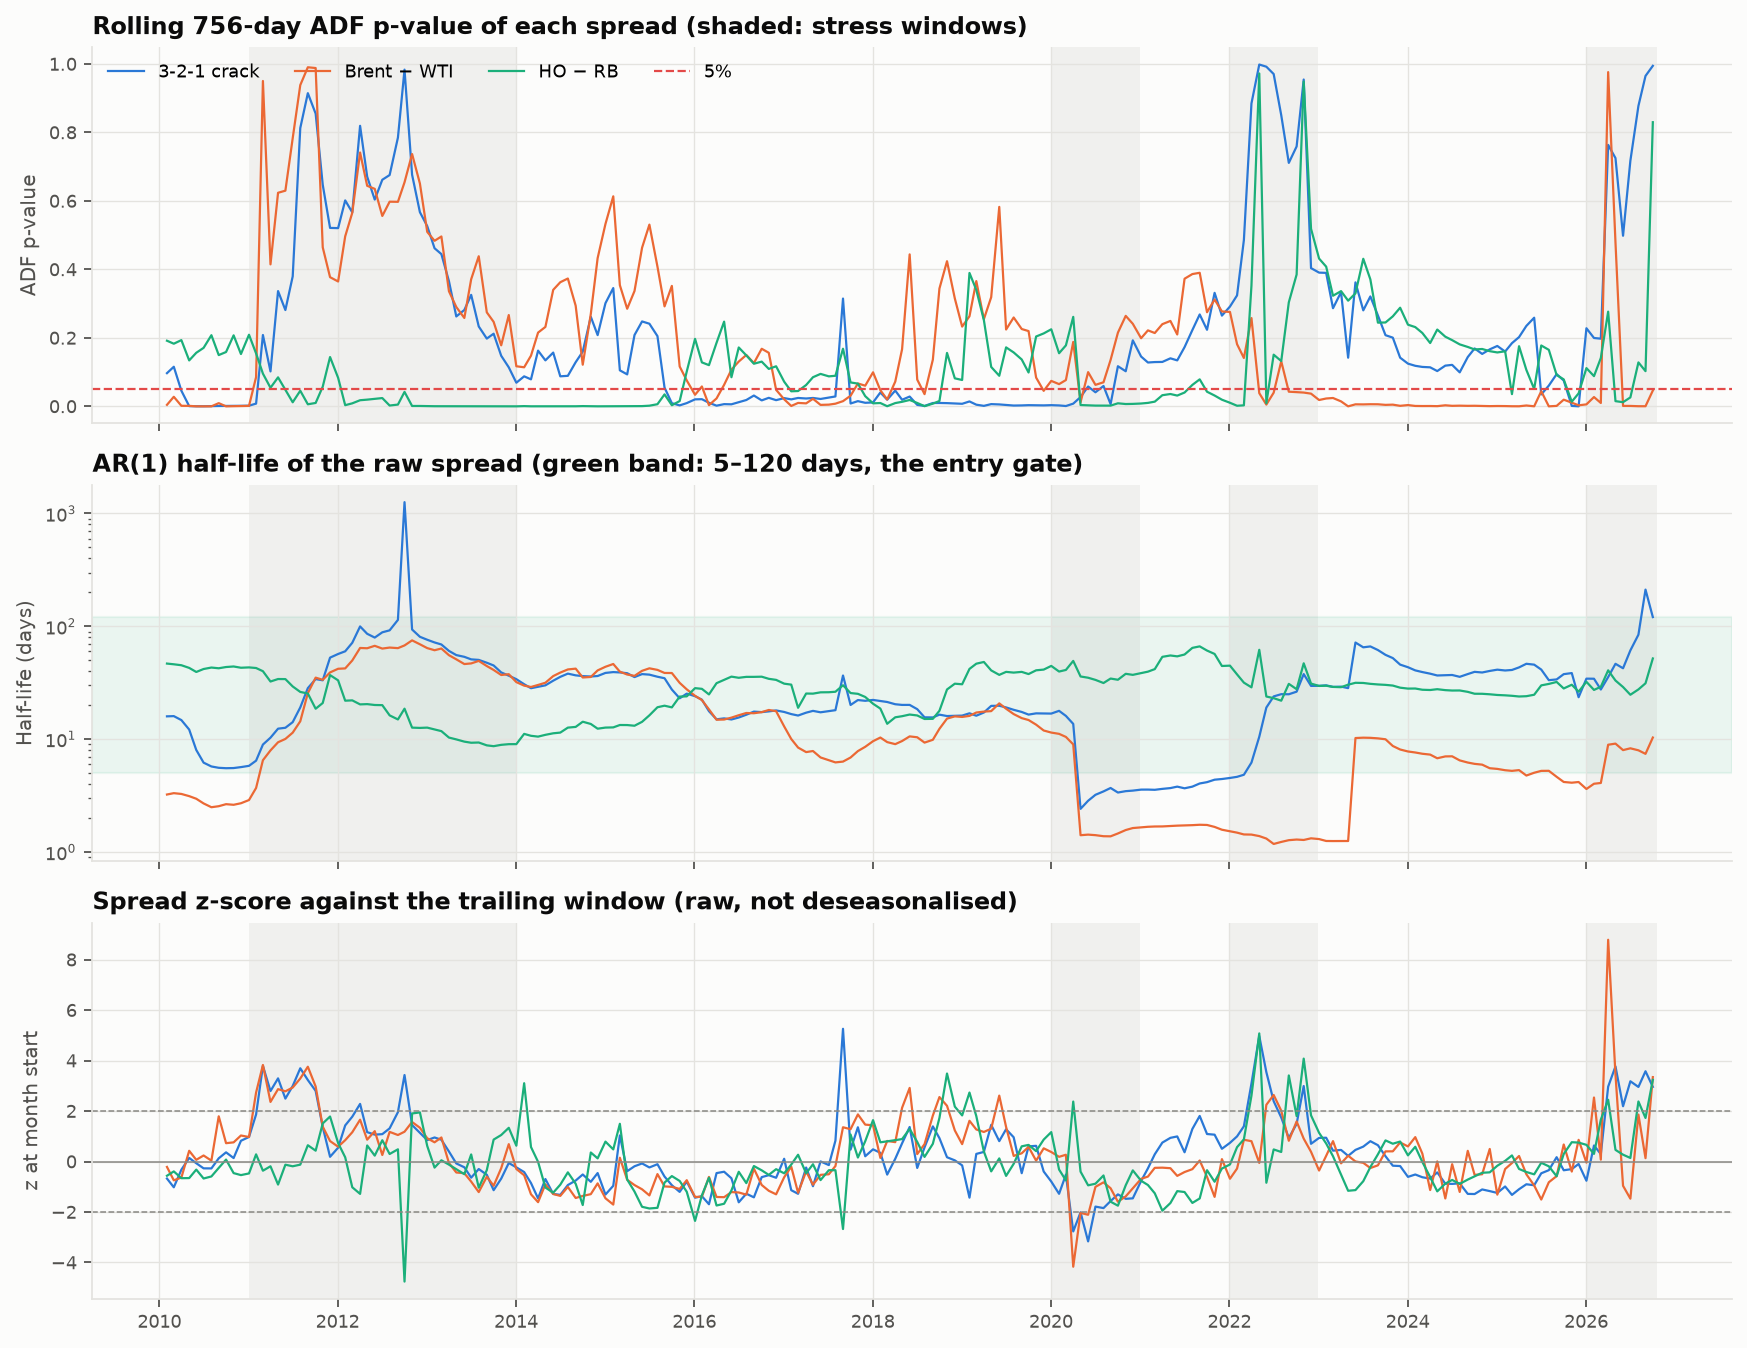

In [3]:
Image(str(F / '03_rolling_stationarity.png'))

In [4]:
read('03_stationarity_summary.csv', index_col=[0, 1]).round(3)

months  adf_pass_rate  adf_p_lt_0.10  median_adf_p  \
spread    period                                                          
crack321  all         201.0          0.353          0.423         0.129   
          2007–2013    47.0          0.234          0.255         0.326   
          2014–2019    72.0          0.694          0.792         0.020   
          2020–2026    82.0          0.122          0.195         0.189   
brent_wti all         201.0          0.408          0.488         0.116   
          2007–2013    47.0          0.255          0.277         0.415   
          2014–2019    72.0          0.250          0.375         0.149   
          2020–2026    82.0          0.634          0.707         0.021   
ho_rb     all         201.0          0.458          0.577         0.077   
          2007–2013    47.0          0.596          0.702         0.022   
          2014–2019    72.0          0.500          0.681         0.054   
          2020–2026    82.0          0.341          0.415         0.153   

                     hl_in_band_rate  median_half_life  
spread    period                                        
crack321  all                  0.871            25.064  
          2007–2013            0.979            39.059  
          2014–2019            1.000            19.953  
          2020–2026            0.695            29.857  
brent_wti all                  0.711             9.397  
          2007–2013            0.723            37.671  
          2014–2019            1.000            17.031  
          2020–2026            0.451             4.146  
ho_rb     all                  1.000            28.345  
          2007–2013            1.000            21.943  
          2014–2019            1.000            24.452  
          2020–2026            1.000            30.731

**What this shows**
- **The plan's breaks show up.** The ADF p-value jumps (stationarity lost) for the crack and Brent–WTI in 2011–13 (the Cushing glut), and for all three spreads in 2022 and 2026.
- **ADF pass rates are low:** 35% (crack), 41% (Brent–WTI) and 46% (HO−RB) of months. As in Project 2, a hard ADF gate would leave few tradeable months. ADF is therefore a filter feature here, not a gate (pre-registered).
- **The half-life entry gate** (5–120 days) is open in 87% of months for the crack, 71% for Brent–WTI and 100% for HO−RB.
- **April 2020 distortion.** Brent–WTI's raw-spread half-life falls to about 1.4 days in every window that contains 20 Apr 2020 (June 2020 to April 2023), so the gate is closed there because reversion looks *too fast*. Without that one week, the median half-life over those months is 9.7 days and the gate is open in 90% of months, against 71%. The crack is affected the same way (4.4 against 32 days). The pre-registered core run keeps the week. The pre-registered robustness run (`drop_flagged_dates`) will show the effect. Futures should not have this spike: the roll leaves the June contract held on 20 Apr 2020.
- **Brent–WTI spot half-lives are very short from 2023 on** (about 4–10 days). That fits the plan's warning that Dated Brent spot is noisy against futures.

In [5]:
read('03_stationarity_by_window.csv', index_col=[0, 1]).round(3)

,,adf_pass_rate,median_adf_p,hl_in_band_rate,median_half_life
spread,window,,,,
crack321,504,0.310,0.145,0.812,19.352
brent_wti,504,0.427,0.089,0.624,7.635
ho_rb,504,0.413,0.079,1.000,26.169
crack321,756,0.353,0.129,0.871,25.064
brent_wti,756,0.408,0.116,0.711,9.397
ho_rb,756,0.458,0.077,1.000,28.345
crack321,1008,0.376,0.098,0.889,31.074
brent_wti,1008,0.349,0.101,0.735,11.588
ho_rb,1008,0.519,0.047,1.000,29.656


## SARIMA on the monthly crack and HO−RB, against naive forecasts

In [6]:
read('03_sarima_vs_naive.csv', index_col=0)[['rmse_sarima', 'rmse_rw', 'rmse_snaive', 'ratio_vs_rw', 'dm_vs_rw_p', 'ratio_vs_snaive', 'dm_vs_snaive_p', 'n_forecasts']].astype(float).round(3)

,rmse_sarima,rmse_rw,rmse_snaive,ratio_vs_rw,dm_vs_rw_p,ratio_vs_snaive,dm_vs_snaive_p,n_forecasts
crack321,4.757,4.643,13.016,1.025,0.251,0.365,0.000,178.0
ho_rb,6.832,6.601,14.719,1.035,0.372,0.464,0.001,178.0


In [7]:
s = json.loads((T / 'analysis_summary.json').read_text())['part3']['sarima']
pd.DataFrame({c: v['residuals'] for c, v in s.items()}).T

,params,aic,lb_p_12,lb_p_24
crack321,"{'intercept': 1.3384, 'ar.L1': 0.9431, 'ar.S.L...",1389.867835,0.173378,0.433071
ho_rb,"{'intercept': 0.9243, 'ar.L1': 0.9162, 'ar.S.L...",1553.305107,0.006966,0.083057


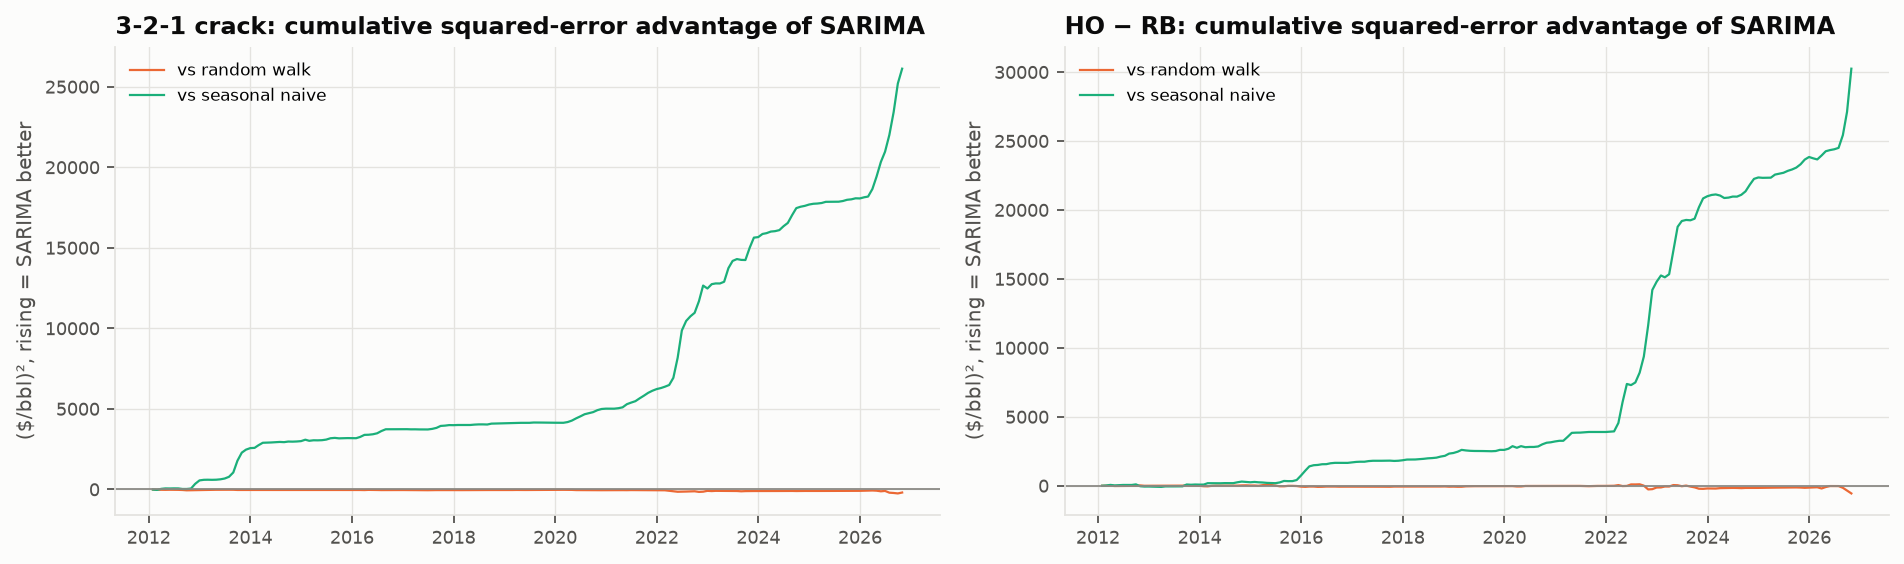

In [8]:
Image(str(F / '03_sarima_vs_naive.png'))

**What this shows**
- **Specification:** SARIMA(1,0,0)(1,0,0)₁₂ with a constant, refit on a rolling 60-month window and forecast one month ahead (178 forecasts, 2012–26).
- **Against the random walk:** SARIMA does not beat "next month = this month". The RMSE ratio is 1.02–1.03 and the Diebold–Mariano p is 0.25–0.37.
- **Against the seasonal naive forecast** ("same month last year"), SARIMA wins easily.
- **Residuals:** Ljung–Box is clean for the crack. HO−RB has leftover autocorrelation at lag 12 (p = 0.007).
- **Implications:** at monthly frequency the spreads are dominated by persistence, and the seasonal AR term is about 0. Seasonality is real (notebook 02) but small next to the level shifts. That supports a seasonal adjustment by simple month means, not a SARIMA forecast, as the fair-value input.

## Long-run link 1: Engle–Granger (Brent on WTI, HO on RB, in $/bbl)

In [9]:
read('03_engle_granger.csv', index_col=0)[['beta', 'beta_se_hac', 't_beta_eq_1', 'eg_p', 'half_life_resid', 'adf_p_fixed_1to1', 'half_life_fixed_1to1', 'n']].astype(float).round(4)

,beta,beta_se_hac,t_beta_eq_1,eg_p,half_life_resid,adf_p_fixed_1to1,half_life_fixed_1to1,n
brent_on_wti,1.0817,0.0136,5.9994,0.0046,13.1015,0.0025,15.9968,4848.0
brent_on_wti_excl_apr2020,1.0845,0.0135,6.2569,0.0078,21.1404,0.0041,25.3637,4843.0
ho_on_rb,1.1760,0.0252,6.9950,0.0061,35.6846,0.0670,52.2058,4848.0


In [10]:
pd.DataFrame(json.loads((T / 'analysis_summary.json').read_text())['part3']['rolling_eg']).T

,eg_pass_rate,median_beta,beta_range
brent_wti,0.437811,1.074572,"[0.37717118346162914, 1.5423018077859925]"
ho_rb,0.358209,1.063541,"[0.5349833804748876, 1.343495262482315]"


- **Brent–WTI:** cointegrated over the full sample (EG p = 0.005). The slope is 1.08, and the indicative HAC test rejects slope = 1 (t ≈ 6). The fixed 1:1 spread is also stationary (ADF p = 0.003), so trading the barrel-neutral 1:1 spread is supported.
- **Rolling estimates are unstable.** The rolling EG passes in only 44% of months, and the rolling slope ranges from 0.38 to 1.54. This is another reason the fixed 1:1 weights (not the estimated β) are traded.
- **HO on RB:** cointegrated (p = 0.006) with slope 1.18. The fixed 1:1 spread is only borderline stationary (p = 0.07).

## Long-run link 2: Johansen on (CL, RB, HO)

In [11]:
read('03_johansen_full.csv', index_col=0).round(3)

,rank,trace_r0,trace_r1,trace_r2,crit95_r0,crit95_r1,crit95_r2,v1_cl,v1_rb,v1_ho,dist_crack321,dist_ho_rb,dist_gasoline_crack,dist_diesel_crack
k_ar_diff=1,3.0,82.233,26.773,5.149,29.796,15.494,3.842,-3.0,4.954,-1.924,0.0,0.0,0.0,0.0
k_ar_diff=10 (AIC),3.0,61.152,18.286,4.242,29.796,15.494,3.842,-3.0,7.113,-3.477,0.0,0.0,0.0,0.0
"k_ar_diff=1, excl Apr 2020",3.0,77.058,23.223,5.154,29.796,15.494,3.842,-3.0,5.451,-2.291,0.0,0.0,0.0,0.0


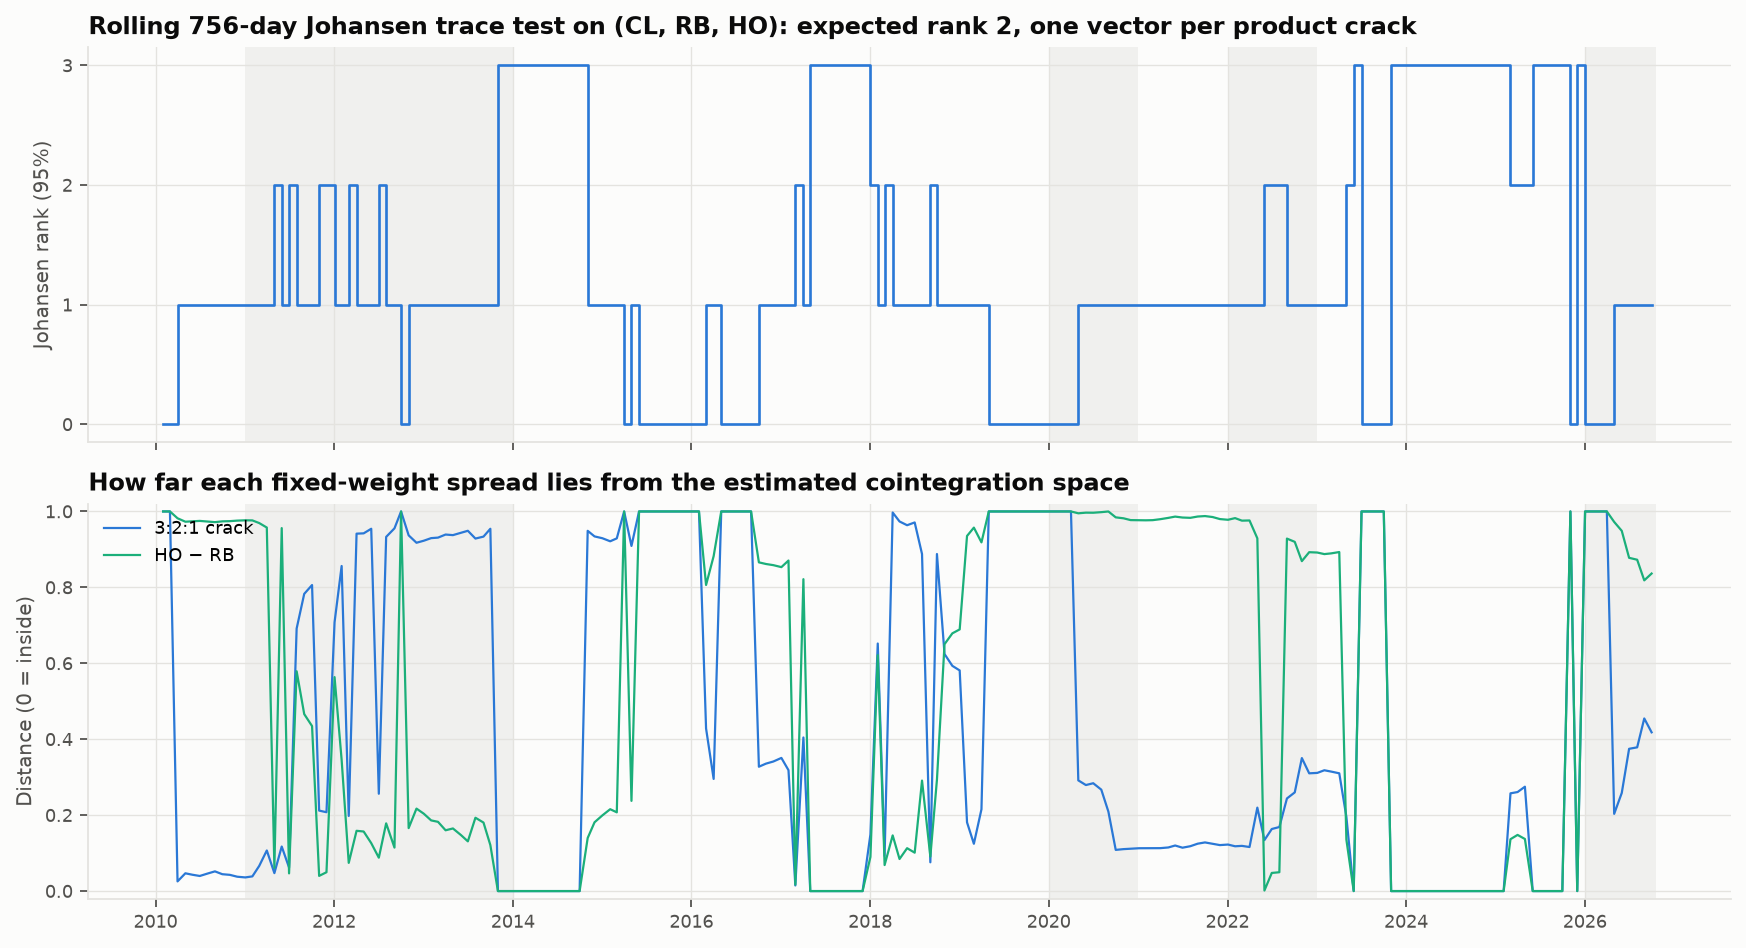

In [12]:
Image(str(F / '03_rolling_johansen.png'))

In [13]:
pd.Series(json.loads((T / 'analysis_summary.json').read_text())['part3']['rolling_johansen'])

rank_share               {'0': 0.194, '1': 0.507, '2': 0.085, '3': 0.214}
median_dist_crack321                                             0.260861
median_v1               {'cl': -3.0, 'rb': 2.271658479684506, 'ho': 0....
dtype: object

**What this shows**
- **The plan expected rank 2** (one vector per product crack). Over the full sample the trace test gives **rank 3**. That is consistent with the ADF finding that the price levels themselves look stationary in 2007–26, and in that case every combination is "cointegrated".
- **The rolling 756-day rank is unstable:**

  | Rank | Share of months |
  |---|---|
  | 0 | 19% |
  | 1 | 51% |
  | 2 | 9% |
  | 3 | 21% |

- **3:2:1 often sits outside the estimated cointegration space** (median distance 0.26, and 1.0 whenever the rank is 0). The median first vector is about (−3, 2.3, 0.0): a gasoline-crack-like relation, with ULSD barely loaded.
- **Implications for the `johansen` variant (pre-registered, crack only, not gated):**
  - The first vector is poorly identified when the rank is 0 or 3.
  - Normalising it to −3 on CL can explode when its CL loading is near zero.
  - Part 4 has to handle those windows. Following the plan, the fixed 3:2:1 spread is traded only because it is itself stationary over the full sample (ADF p = 0.001).